<a href="https://colab.research.google.com/github/candeperles/PDI-TP/blob/main/notebooks/01_exploracion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Exploración de los datos

Qué hay en el dataset, cuánto de cada cosa, de dónde vienen las imágenes, cómo son las cajas,
y cómo queda la división train/val compartida.

In [ ]:
# --- Setup: correr siempre primero ---
import os
import subprocess
import sys
from pathlib import Path

INTEGRANTE = os.environ.get("PDI_INTEGRANTE", "nombre")  # reemplazar por tu nombre

if "google.colab" in sys.modules:
    repo = Path("/content/PDI-TP")
    if repo.is_dir():
        subprocess.run(["git", "-C", str(repo), "pull", "--ff-only", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", "https://github.com/candeperles/PDI-TP.git", str(repo)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(repo / "requirements.txt")], check=True)
else:
    # Funciona al abrir Jupyter desde la raíz o desde notebooks/.
    repo = next((p for p in (Path.cwd(), Path.cwd().parent)
                 if (p / "pdi_tp" / "entorno.py").is_file()), None)
    if repo is None:
        raise FileNotFoundError("Abrí Jupyter desde la raíz del repositorio o desde notebooks/.")
os.chdir(repo)
sys.path.insert(0, str(repo))

from pdi_tp import entorno, datos, resultados, split
rutas = entorno.preparar(INTEGRANTE)


## Tabla de imágenes y de cajas

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

pd.set_option("display.precision", 2)
plt.rcParams["figure.dpi"] = 72
CLASES = {0: "clase 0", 1: "clase 1", 2: "clase 2"}

imagenes = datos.listar_imagenes(rutas)
tabla = split.tabla_imagenes(rutas)  # archivo, fuente, grupo espacial, con_paneles

filas_img, filas_caja = [], []
for img in imagenes:
    c = datos.leer_cajas(datos.label_de(rutas, img))
    with Image.open(img) as im:
        modo = im.mode
        rgb = np.asarray(im.convert("RGB"), dtype=float)
    filas_img.append({"archivo": img.name, "modo": modo, "n_cajas": len(c),
                      "brillo": rgb.mean(), "contraste": rgb.std()})
    for clase, xc, yc, w, h in c:
        filas_caja.append({"archivo": img.name, "clase": int(clase), "xc": xc, "yc": yc,
                           "w_px": w * 256, "h_px": h * 256})

img_df = tabla.merge(pd.DataFrame(filas_img), on="archivo")
cajas = pd.DataFrame(filas_caja).merge(tabla[["archivo", "fuente"]], on="archivo")
cajas["area_px"] = cajas["w_px"] * cajas["h_px"]
cajas["aspecto"] = cajas["w_px"] / cajas["h_px"]
print(f"{len(img_df)} imágenes, {len(cajas)} cajas, {img_df['grupo'].nunique()} grupos espaciales")
img_df.head()

900 imágenes, 2669 cajas, 187 grupos espaciales


,archivo,fuente,grupo,con_paneles,modo,n_cajas,brillo,contraste
0,2161488_unknown_17.969541515267093_-76.7934515...,geo,0,False,P,0,145.61,52.61
1,2161488_unknown_17.969541515267093_-76.7934515...,geo,0,False,P,0,144.39,60.80
2,2161576_unknown_18.02672120400235_-76.83812296...,geo,1,False,P,0,152.07,50.93
3,2161719_unknown_17.97698301995914_-76.77939693...,geo,2,False,P,0,168.95,53.13
4,2161719_unknown_17.97698301995914_-76.77939693...,geo,2,False,P,0,155.46,46.47


## Balance de clases

Dos niveles: por imagen (clasificación: con/sin paneles) y por caja (detección: clases 0, 1, 2).

Imágenes que contienen cada clase:
clase
0    749
1      6
2      9
Name: archivo, dtype: int64


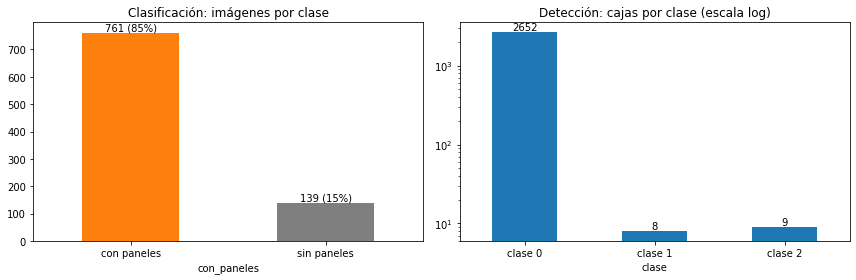

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

por_img = img_df["con_paneles"].map({True: "con paneles", False: "sin paneles"}).value_counts()
por_img.plot.bar(ax=axs[0], color=["tab:orange", "tab:gray"], rot=0,
                 title="Clasificación: imágenes por clase")
for i, v in enumerate(por_img):
    axs[0].text(i, v, f"{v} ({v / len(img_df):.0%})", ha="center", va="bottom")

por_caja = cajas["clase"].map(CLASES).value_counts().sort_index()
por_caja.plot.bar(ax=axs[1], logy=True, rot=0, title="Detección: cajas por clase (escala log)")
for i, v in enumerate(por_caja):
    axs[1].text(i, v, str(v), ha="center", va="bottom")
plt.tight_layout()

print("Imágenes que contienen cada clase:")
print(cajas.groupby("clase")["archivo"].nunique())

## Fuentes de las imágenes

Por el nombre de archivo, las imágenes vienen de 4 fuentes distintas:

| fuente | nombre | qué codifica |
|---|---|---|
| `solarpanels_hd` | `solarpanels_hd_<n>__x0_<x>_y0_<y>_dxdy_832_<i>_<j>` | recorte de 832 px en (x, y), subdividido en tiles |
| `PV01` | `PV01_<x>_<y>` | coordenadas de tile |
| `kingston` | `kingston_<n>_...`, `kingston2_<a>_<b>_<k>` | imagen grande `n` (Kingston, Jamaica) |
| `geo` | `<id>_unknown_<lat>_<lon>_<i>_<j>` | latitud y longitud |

In [4]:
por_fuente = img_df.groupby("fuente").agg(
    imagenes=("archivo", "size"),
    grupos=("grupo", "nunique"),
    sin_paneles=("con_paneles", lambda s: (~s).sum()),
    cajas_por_img=("n_cajas", "mean"),
    max_cajas=("n_cajas", "max"),
    modo_P=("modo", lambda s: (s == "P").sum()),
    brillo=("brillo", "mean"),
)
por_fuente["%_sin_paneles"] = por_fuente["sin_paneles"] / por_fuente["imagenes"] * 100
por_fuente = por_fuente.join(cajas.groupby("fuente")[["w_px", "h_px"]].median().add_prefix("mediana_"))
por_fuente

,imagenes,grupos,sin_paneles,cajas_por_img,max_cajas,modo_P,brillo,%_sin_paneles,mediana_w_px,mediana_h_px
fuente,,,,,,,,,,
PV01,228,54,0,7.63,37,0,131.23,0.00,61.00,33.50
geo,73,29,58,0.27,3,54,133.92,79.45,56.00,53.50
kingston,99,10,45,1.15,7,0,94.21,45.45,42.00,43.00
solarpanels_hd,500,94,36,1.59,15,0,101.42,7.20,61.54,54.15


De dónde vienen las imágenes SIN paneles:
fuente
geo               58
kingston          45
solarpanels_hd    36
Name: count, dtype: int64


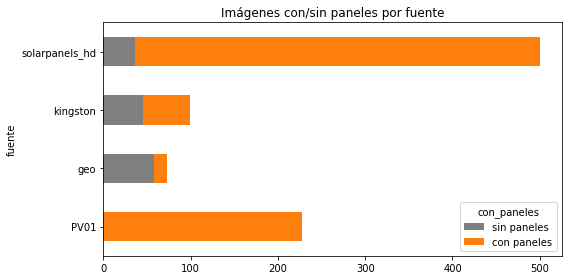

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
(img_df.groupby(["fuente", "con_paneles"]).size().unstack(fill_value=0)
       .rename(columns={True: "con paneles", False: "sin paneles"})
       .plot.barh(stacked=True, ax=ax, color={"con paneles": "tab:orange", "sin paneles": "tab:gray"}))
ax.set_title("Imágenes con/sin paneles por fuente")
plt.tight_layout()

print("De dónde vienen las imágenes SIN paneles:")
print(img_df.loc[~img_df["con_paneles"], "fuente"].value_counts())

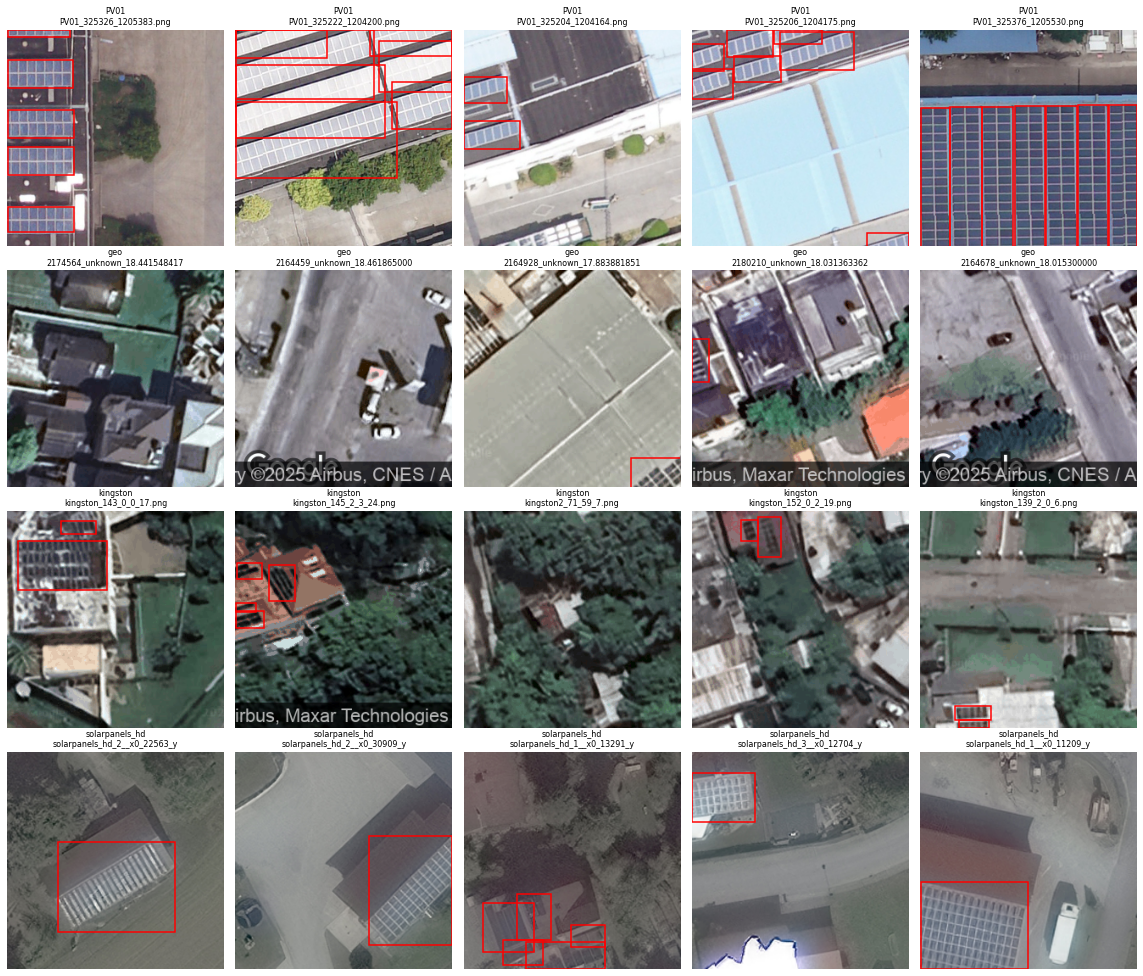

In [6]:
# 5 ejemplos por fuente, con cajas
rng = np.random.default_rng(0)
fuentes = sorted(img_df["fuente"].unique())
fig, axs = plt.subplots(len(fuentes), 5, figsize=(16, 3.4 * len(fuentes)))
for fila, f in zip(axs, fuentes):
    archivos = rng.choice(img_df.loc[img_df["fuente"] == f, "archivo"], 5, replace=False)
    for ax, a in zip(fila, archivos):
        datos.dibujar_cajas(ax, rutas, rutas.imagenes / a)
        ax.set_title(f"{f}\n{a[:28]}", fontsize=8)
plt.tight_layout()

## Cajas: cantidad, tamaño y forma

Cajas chicas (√área < 16 px): 170 (6%)
Cajas grandes (√área > 128 px): 69 (3%)
Cajas 'astilla' (< 3 px de ancho o alto): 38, pegadas al borde: 38
fuente           PV01    geo  kingston  solarpanels_hd
w_px    count  1740.0   20.0     114.0           795.0
        mean     74.4   58.5      46.2            70.4
        std      55.9   36.8      23.4            39.3
        min       1.0   17.0       8.0             0.0
        25%      34.0   32.2      32.0            44.3
        50%      61.0   56.0      42.0            61.5
        75%      99.0   74.2      55.0            87.4
        max     256.0  174.0     158.0           256.0
h_px    count  1740.0   20.0     114.0           795.0
        mean     44.3   61.6      44.3            59.0
        std      38.0   43.3      21.0            33.3
        min       1.0   15.0      10.0             1.2
        25%      22.0   33.7      30.3            34.5
        50%      33.5   53.5      43.0            54.2
        75%      50.0   74.5 

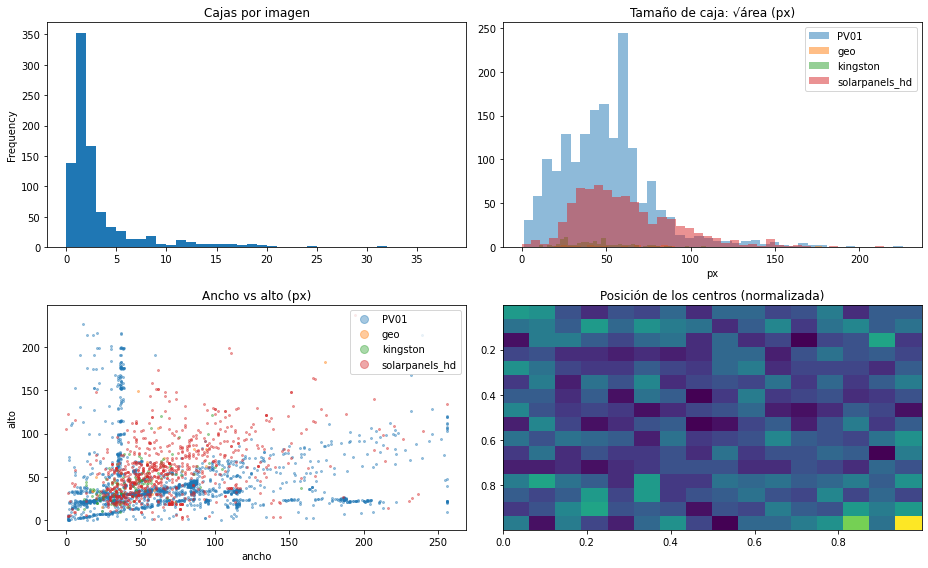

In [7]:
fig, axs = plt.subplots(2, 2, figsize=(13, 8))
img_df["n_cajas"].plot.hist(bins=range(0, img_df["n_cajas"].max() + 2), ax=axs[0, 0],
                            title="Cajas por imagen")
for f, g in cajas.groupby("fuente"):
    axs[0, 1].hist(np.sqrt(g["area_px"]), bins=40, alpha=0.5, label=f)
axs[0, 1].set(title="Tamaño de caja: √área (px)", xlabel="px")
axs[0, 1].legend()
for f, g in cajas.groupby("fuente"):
    axs[1, 0].scatter(g["w_px"], g["h_px"], s=4, alpha=0.4, label=f)
axs[1, 0].set(title="Ancho vs alto (px)", xlabel="ancho", ylabel="alto")
axs[1, 0].legend(markerscale=4)
axs[1, 1].hist2d(cajas["xc"], cajas["yc"], bins=16, cmap="viridis")
axs[1, 1].set(title="Posición de los centros (normalizada)")
axs[1, 1].invert_yaxis()
plt.tight_layout()

lado = np.sqrt(cajas["area_px"])
print(f"Cajas chicas (√área < 16 px): {(lado < 16).sum()} ({(lado < 16).mean():.0%})")
print(f"Cajas grandes (√área > 128 px): {(lado > 128).sum()} ({(lado > 128).mean():.0%})")
astillas = cajas[(cajas["w_px"] < 3) | (cajas["h_px"] < 3)]
print(f"Cajas 'astilla' (< 3 px de ancho o alto): {len(astillas)}, "
      f"pegadas al borde: {((astillas[['xc', 'yc']] < 0.02) | (astillas[['xc', 'yc']] > 0.98)).any(axis=1).sum()}")
print(cajas.groupby("fuente")[["w_px", "h_px", "aspecto"]].describe().T.round(1))

## Clases raras (1 y 2)

Hay 17 cajas entre las dos. En `solarpanels_hd` los IDs representan confianza moderada/baja, según el artículo original (ver `docs/criterios_datos.md`). No son tecnologías distintas.

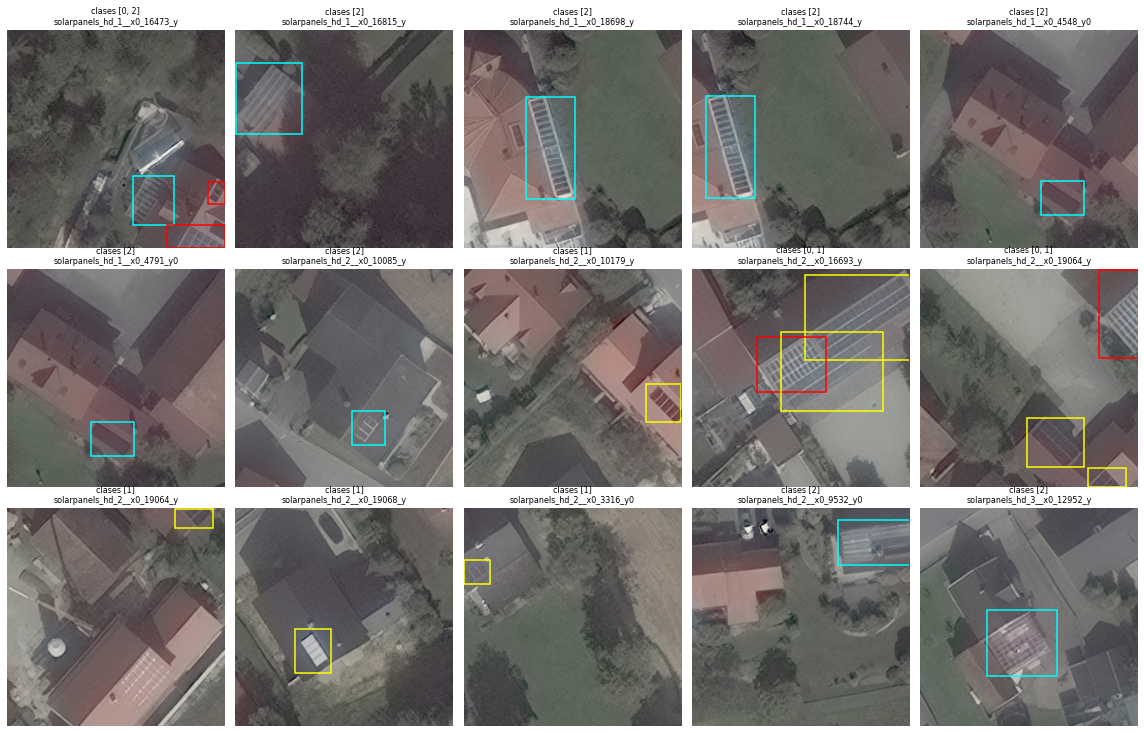

In [8]:
raras = sorted(cajas.loc[cajas["clase"] > 0, "archivo"].unique())
fig, axs = plt.subplots(int(np.ceil(len(raras) / 5)), 5, figsize=(16, 3.4 * np.ceil(len(raras) / 5)))
for ax in axs.flat:
    ax.set_axis_off()
for ax, a in zip(axs.flat, raras):
    datos.dibujar_cajas(ax, rutas, rutas.imagenes / a)  # rojo = 0, amarillo = 1, cian = 2
    clases = sorted(int(c) for c in cajas.loc[cajas["archivo"] == a, "clase"].unique())
    ax.set_title(f"clases {clases}\n{a[:28]}", fontsize=8)
plt.tight_layout()

## Recortes vecinos: riesgo de fuga entre train y val

Muchas imágenes son tiles contiguos de una misma imagen grande. Si un tile cae en train y su vecino
en val, el modelo "ya vio" casi la misma escena y la validación da mejor de lo que es.
Por eso `split.tabla_imagenes` agrupa las imágenes por cercanía espacial (columna `grupo`).

Grupos espaciales: 187   tamaño mediano: 2   máximo: 84
                count  50%   max
fuente                          
PV01             54.0  2.0  84.0
geo              29.0  2.0  14.0
kingston         10.0  6.0  30.0
solarpanels_hd   94.0  3.0  32.0


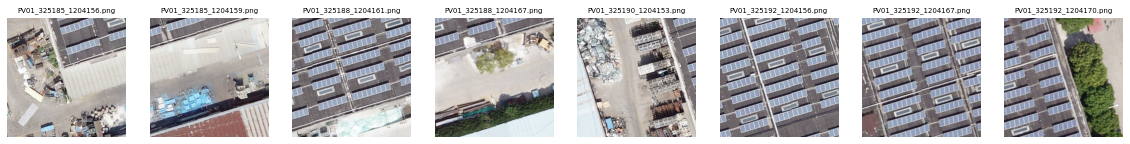

In [9]:
tam = img_df.groupby(["fuente", "grupo"]).size()
print(f"Grupos espaciales: {len(tam)}   tamaño mediano: {tam.median():.0f}   máximo: {tam.max()}")
print(tam.groupby("fuente").describe()[["count", "50%", "max"]])

# Un grupo PV01 grande, para ver qué tan parecidos son los vecinos
grupo = tam.loc["PV01"].idxmax()
vecinos = sorted(img_df.loc[img_df["grupo"] == grupo, "archivo"])[:8]
fig, axs = plt.subplots(1, 8, figsize=(20, 3))
for ax, a in zip(axs, vecinos):
    ax.imshow(datos.leer_imagen(rutas.imagenes / a))
    ax.set_title(a, fontsize=7)
    ax.set_axis_off()

## División train/val

Generada con `scripts/make_split.py` (ver criterio en `pdi_tp/split.py`):
**80/20 por grupos espaciales**, estratificada por fuente + con/sin paneles. Está versionada en
`splits/`, así que todo el equipo usa exactamente la misma.

In [10]:
conjuntos = split.cargar_split(rutas)
img_df["split"] = img_df["archivo"].map({p.name: s for s, ps in conjuntos.items() for p in ps})

print(img_df["split"].value_counts(), "\n")
print("Grupos espaciales compartidos entre train y val:",
      len(set(img_df.loc[img_df["split"] == "train", "grupo"]) & set(img_df.loc[img_df["split"] == "val", "grupo"])))

resumen = img_df.groupby(["split", "fuente"])["con_paneles"].agg(imagenes="size", sin_paneles=lambda s: (~s).sum())
resumen["%_sin_paneles"] = resumen["sin_paneles"] / resumen["imagenes"] * 100
display(resumen)

cajas["split"] = cajas["archivo"].map(img_df.set_index("archivo")["split"])
cajas.groupby(["split", "clase"]).size().unstack(fill_value=0)

split
train    738
val      162
Name: count, dtype: int64 

Grupos espaciales compartidos entre train y val: 0


imagenes  sin_paneles  %_sin_paneles
split fuente                                              
train PV01                 188            0           0.00
      geo                   62           51          82.26
      kingston              87           40          45.98
      solarpanels_hd       401           28           6.98
val   PV01                  40            0           0.00
      geo                   11            7          63.64
      kingston              12            5          41.67
      solarpanels_hd        99            8           8.08

clase,0,1,2
split,,,
train,2086,4,7
val,566,4,2


## Observaciones

Lo que surge de la exploración (revisar con los gráficos de arriba):

- **Desbalance en clasificación:** ~85 % de las imágenes tiene paneles. Un modelo que siempre dice
  "con paneles" ya tiene ~85 % de accuracy → reportar precision/recall/F1 y matriz de confusión, y
  considerar pesos de clase.
- **Las imágenes sin paneles vienen casi solo de `geo` y `kingston`; PV01 no tiene ninguna.** Las fuentes
  difieren en brillo, resolución y modo de color (las PNG en modo paleta son todas de `geo`), así que un
  clasificador podría aprender a reconocer la *fuente* en vez de los paneles. Conviene mirar los errores
  por fuente.
- **Detección:** en `solarpanels_hd` los IDs 0/1/2 indican confianza alta/moderada/baja, no tipos de objeto. Se definió una clase "panel" para el futuro derivado, preservando la confianza original (ver `docs/criterios_datos.md`).
- **Cajas muy variadas:** desde unos pocos px (paneles residenciales) hasta casi toda la imagen
  (instalaciones grandes, sobre todo en PV01). Las cajas chicas van a ser las difíciles.
- **PV01** tiene muchas cajas por imagen (instalaciones grandes cubiertas de paneles) y pesa mucho en el
  total de cajas: domina las métricas de detección.
- **Cajas "astilla":** hay cajas de 1-2 px de ancho o alto pegadas al borde: paneles cortados al
  recortar los tiles. Se conservan las 37 cajas positivas; la caja adicional de ancho cero se excluirá en el futuro derivado. El umbral de 3 px se usa para revisión, sin filtro automático.
- **Clases 1 y 2:** la hipótesis visual previa sobre tipos de panel no estaba confirmada. El cotejo con Figshare verificó sus niveles de confianza. Ver `notebooks/03_revision_anotaciones.ipynb`.
- **Marca de agua** en algunas imágenes de `kingston` ("Imagery ©2025 Airbus..."): otro posible atajo.
- **Recortes vecinos:** el split se hizo por grupos espaciales para evitar fuga entre train y val.